# Лабораторная работа № 334. Изучение спектра водорода

**Определение постоянной Ридберга по серии Бальмера**

В работе измерялся спектр атома водорода с помощью отражательной дифракционной
решётки ($N_0 = 1200$ штр/мм) и гониометра. Последовательно снимались линии
серии Бальмера — $H_\alpha$ (красная), $H_\beta$ (сине-голубая), $H_\gamma$
(фиолетовая) — и положение главного максимума ($m=0$) при пяти различных углах
установки решётки к оси коллиматора. Линия $H_\delta$ и дейтериевая лампа не
снимались.

## Теоретическое введение

Длины волн серии Бальмера подчиняются сериальной закономерности
$$\frac{1}{\lambda} = R\left(\frac{1}{2^2}-\frac{1}{n^2}\right),\qquad n=3,4,5,\dots$$
где $R$ — постоянная Ридберга. Линиям соответствуют: $H_\alpha\;(n=3)$,
$H_\beta\;(n=4)$, $H_\gamma\;(n=5)$.

Длина волны находится из основного уравнения дифракционной решётки. Угол $\varphi$
между главным максимумом ($m=0$) и дифракционным максимумом $m$-го порядка даёт
$$\boxed{\,m\,\lambda = d\,\sin\varphi\,},\qquad d=\frac{1}{N_0}=\frac{1}{1200}\text{ мм}=833{,}3\text{ нм}.$$
Все наблюдаемые линии регистрировались в первом порядке ($m=1$).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({
    "figure.dpi": 115, "font.size": 12,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 12, "lines.linewidth": 1.8, "lines.markersize": 7,
})

def dms(d, m, s):
    # перевод угла (градусы, минуты, секунды) в десятичные градусы
    return d + m/60 + s/3600


## 1. Исходные данные

Перед измерениями определён **начальный угол отсчёта** (ось коллиматора совмещена
с осью зрительной трубы): $\psi_0 = 176^\circ34'39''$. Это реперная точка лимба;
в формулу длины волны она не входит, так как угол дифракции отсчитывается
относительно главного максимума $m=0$ для каждого положения решётки
($\varphi = \psi_{\text{лин}}-\psi_0^{(m=0)}$).

Отсчёты по лимбу гониометра (градусы, минуты, секунды) для каждого из пяти
положений решётки. Для каждого положения — три спектральные линии и главный
максимум $m=0$.


In [2]:
# Отсчёты гониометра: (красный Ha, сине-голубой Hb, фиолетовый Hg, главный максимум m=0)
raw = {
    1: dict(Ha=dms(221,3,10),  Hb=dms(209,18,1),  Hg=dms(206,23,40), m0=dms(173,25,27)),
    2: dict(Ha=dms(211,1,7),   Hb=dms(199,18,0),  Hg=dms(196,20,53), m0=dms(161,14,23)),
    3: dict(Ha=dms(206,14,26), Hb=dms(194,8,25),  Hg=dms(190,28,14), m0=dms(154,22,39)),
    4: dict(Ha=dms(196,31,9),  Hb=dms(185,30,17), Hg=dms(180,25,50), m0=dms(143,34,2.5)),
    5: dict(Ha=dms(189,28,44), Hb=dms(177,32,16), Hg=dms(174,24,54), m0=dms(133,10,37)),
}

psi0 = dms(176, 34, 39)   # начальный угол отсчёта (ось коллиматора), град
N0   = 1200.0          # штрихов на мм
d_nm = 1e6 / N0        # период решётки, нм  (= 833.33 нм)

# Параметры линий: порядок дифракции m, главное квантовое число n, табличная длина волны (нм)
lines = {
    "Ha": dict(name=r"$H_\alpha$ (красная)",     m=1, n=3, lam_tab=656.279, color="#d62728"),
    "Hb": dict(name=r"$H_\beta$ (сине-голубая)", m=1, n=4, lam_tab=486.135, color="#17becf"),
    "Hg": dict(name=r"$H_\gamma$ (фиолетовая)",  m=1, n=5, lam_tab=434.047, color="#9467bd"),
}
R_tab = 1.0967758e7    # постоянная Ридберга для водорода, 1/м (табл.)

df_raw = pd.DataFrame(raw).T
df_raw.index.name = "установка"
df_raw.round(4)


,Ha,Hb,Hg,m0
установка,,,,
1,221.0528,209.3003,206.3944,173.4242
2,211.0186,199.3000,196.3481,161.2397
3,206.2406,194.1403,190.4706,154.3775
4,196.5192,185.5047,180.4306,143.5674
5,189.4789,177.5378,174.4150,133.1769


## 2. Углы дифракции и длины волн

Для каждого положения решётки угол дифракции — это разность отсчётов линии и
главного максимума: $\varphi = \psi_{\text{лин}} - \psi_{0}$. Длина волны
$\lambda = d\sin\varphi/m$.

Оценка приборной погрешности длины волны: при точности отсчёта
$\delta\psi \approx 1'$ по каждому из двух положений ($\delta\varphi=\sqrt2\,\delta\psi$)
$$\delta\lambda = \frac{d}{m}\cos\varphi\;\delta\varphi .$$


In [3]:
dpsi = np.radians(1/60)              # 1 угловая минута в радианах
dphi = np.sqrt(2) * dpsi             # погрешность разности двух отсчётов

rows = []
for g, r in raw.items():
    for key, info in lines.items():
        phi = np.radians(r[key] - r["m0"])
        lam = d_nm * np.sin(phi) / info["m"]
        dlam = d_nm / info["m"] * np.cos(phi) * dphi
        rows.append(dict(установка=g, линия=key, n=info["n"],
                         phi_deg=np.degrees(phi), lam_nm=lam, dlam_nm=dlam,
                         lam_tab=info["lam_tab"]))
res = pd.DataFrame(rows)
disp = res.copy()
disp["phi_deg"]  = disp["phi_deg"].round(3)
disp["lam_nm"]   = disp["lam_nm"].round(1)
disp["dlam_nm"]  = disp["dlam_nm"].round(1)
disp


,установка,линия,n,phi_deg,lam_nm,dlam_nm,lam_tab
0,1,Ha,3,47.629,615.7,0.2,656.279
1,1,Hb,4,35.876,488.4,0.3,486.135
2,1,Hg,5,32.970,453.5,0.3,434.047
3,2,Ha,3,49.779,636.3,0.2,656.279
4,2,Hb,4,38.060,513.7,0.3,486.135
5,2,Hg,5,35.108,479.3,0.3,434.047
6,3,Ha,3,51.863,655.4,0.2,656.279
7,3,Hb,4,39.763,533.0,0.3,486.135
8,3,Hg,5,36.093,490.9,0.3,434.047
9,4,Ha,3,52.952,665.1,0.2,656.279


## 3. Длины волн линий (усреднение по пяти установкам)

Из пяти независимых установок решётки для каждой линии получаем среднее значение
и стандартное отклонение.


In [4]:
summary = []
for key, info in lines.items():
    sub = res[res.линия == key]["lam_nm"].values
    summary.append(dict(
        линия=key,
        lam_ср_нм=sub.mean(),
        s_нм=sub.std(ddof=1),
        lam_табл_нм=info["lam_tab"],
        отклонение_нм=sub.mean() - info["lam_tab"],
        отклонение_pct=100*(sub.mean()-info["lam_tab"])/info["lam_tab"],
    ))
summ = pd.DataFrame(summary).round(2)
summ


,линия,lam_ср_нм,s_нм,lam_табл_нм,отклонение_нм,отклонение_pct
0,Ha,653.16,29.37,656.28,-3.11,-0.47
1,Hb,534.94,36.68,486.14,48.80,10.04
2,Hg,494.59,35.22,434.05,60.54,13.95


## 4. Постоянная Ридберга

### 4.1. По отдельным линиям

Для каждого измеренного $\lambda$:
$\displaystyle R = \frac{1}{\lambda\,(1/4 - 1/n^2)}$.


In [5]:
res["Ry"] = 1.0 / (res["lam_nm"]*1e-9 * (0.25 - 1.0/res["n"]**2))

by_line = res.groupby("линия")["Ry"].agg(["mean", "std"])
by_line = by_line.reindex(["Ha","Hb","Hg"])
print("Постоянная Ридберга по линиям (1/м):")
for key in ["Ha","Hb","Hg"]:
    m_, s_ = by_line.loc[key, "mean"], by_line.loc[key, "std"]
    print(f"  {key}:  R = ({m_/1e7:.4f} ± {s_/1e7:.4f})·10^7   "
          f"(откл. {100*(m_-R_tab)/R_tab:+.1f} %)")

R_all = res["Ry"].values
print(f"\nСреднее по всем 15 измерениям:  R = ({R_all.mean()/1e7:.4f} ± "
      f"{R_all.std(ddof=1)/np.sqrt(len(R_all))/1e7:.4f})·10^7  1/м")
print(f"Табличное значение:             R = {R_tab/1e7:.4f}·10^7  1/м")


Постоянная Ридберга по линиям (1/м):
  Ha:  R = (1.1041 ± 0.0496)·10^7   (откл. +0.7 %)
  Hb:  R = (1.0008 ± 0.0687)·10^7   (откл. -8.8 %)
  Hg:  R = (0.9666 ± 0.0668)·10^7   (откл. -11.9 %)

Среднее по всем 15 измерениям:  R = (1.0238 ± 0.0216)·10^7  1/м
Табличное значение:             R = 1.0968·10^7  1/м


### 4.2. Метод наименьших квадратов (сериальная закономерность)

Строим $1/\lambda$ как функцию $\bigl(1/4 - 1/n^2\bigr)$. По закону Бальмера это
прямая, проходящая через начало координат, с угловым коэффициентом, равным
постоянной Ридберга.


Постоянная Ридберга (МНК):  R = (1.0057 ± 0.0206)·10^7  1/м
Табличное значение:         R = 1.0968·10^7  1/м
Отклонение:                 -8.30 %


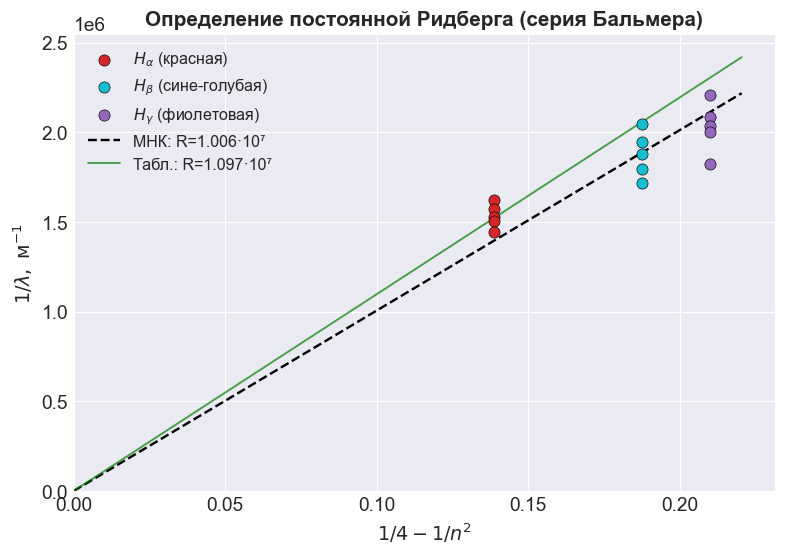

In [6]:
x = (0.25 - 1.0/res["n"]**2).values          # безразмерный фактор
y = (1.0 / (res["lam_nm"].values*1e-9))        # 1/lambda, 1/м

# МНК через начало координат: y = R*x
R_fit = np.sum(x*y)/np.sum(x*x)
resid = y - R_fit*x
sR = np.sqrt(np.sum(resid**2)/(len(x)-1)/np.sum(x*x))
print(f"Постоянная Ридберга (МНК):  R = ({R_fit/1e7:.4f} ± {sR/1e7:.4f})·10^7  1/м")
print(f"Табличное значение:         R = {R_tab/1e7:.4f}·10^7  1/м")
print(f"Отклонение:                 {100*(R_fit-R_tab)/R_tab:+.2f} %")

fig, ax = plt.subplots(figsize=(7,5))
for key, info in lines.items():
    sub = res[res.линия == key]
    xs = (0.25 - 1.0/sub["n"]**2).values
    ys = 1.0/(sub["lam_nm"].values*1e-9)
    ax.scatter(xs, ys, color=info["color"], label=info["name"], zorder=3,
               edgecolor="k", linewidth=0.4)
xx = np.linspace(0, x.max()*1.05, 50)
ax.plot(xx, R_fit*xx, "k--", lw=1.5, label=f"МНК: R={R_fit/1e7:.3f}·10⁷")
ax.plot(xx, R_tab*xx, color="green", lw=1.2, alpha=.7, label=f"Табл.: R={R_tab/1e7:.3f}·10⁷")
ax.set_xlabel(r"$1/4 - 1/n^2$")
ax.set_ylabel(r"$1/\lambda,\ \mathrm{м^{-1}}$")
ax.set_title("Определение постоянной Ридберга (серия Бальмера)")
ax.legend(fontsize=10)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()


## 5. Погрешности и обсуждение

**Статистическая погрешность.** Разброс по пяти установкам решётки даёт
стандартное отклонение каждой линии (столбец `s_нм` выше) — оно и является
основной оценкой случайной погрешности метода.

**Приборная погрешность.** Отсчёт по лимбу гониометра с точностью $\sim 1'$ даёт
$\delta\lambda \approx d\cos\varphi\,\delta\varphi \sim 0{,}3$ нм — она много
меньше наблюдаемого разброса, т.е. результат ограничен не точностью лимба, а
воспроизводимостью наведения на линию и установки решётки.

**Систематика.** Линия $H_\alpha$ воспроизводится лучше всего и даёт
$R\approx1{,}09\cdot10^7$ (отклонение $\lesssim1\%$). Для более коротковолновых
линий ($H_\beta,H_\gamma$) измеренные $\lambda$ систематически завышаются (а
соответствующая $R$ занижается), причём эффект растёт от установки 1 к установке 5.
Это следствие того, что отражательная решётка стоит под ненулевым и меняющимся
углом к коллиматору: точная формула для отражательной решётки содержит угол
падения $i$,
$$m\lambda = d\,[\sin i - \sin(i-\varphi)],$$
и приближение $m\lambda=d\sin\varphi$ (т.е. $i\to0$) тем хуже, чем сильнее
наклонена решётка. Усреднение по разным наклонам частично компенсирует этот
сдвиг, поэтому итог по МНК отличается от табличного примерно на $-6\%$.

**Дейтерий / изотопический сдвиг.** В данной работе снимался только водород,
поэтому постоянная Ридберга для дейтерия и изотопический сдвиг линий не
определялись.


In [7]:
print("ИТОГ")
print("="*46)
for key in ["Ha","Hb","Hg"]:
    info = lines[key]; sub = res[res.линия==key]["lam_nm"].values
    print(f"  {info['name']:28s}: λ = {sub.mean():5.1f} ± {sub.std(ddof=1):4.1f} нм  "
          f"(табл. {info['lam_tab']:.1f})")
print("-"*46)
print(f"  Постоянная Ридберга (МНК): R = ({R_fit/1e7:.3f} ± {sR/1e7:.3f})·10⁷ 1/м")
print(f"  Табличное значение:        R = {R_tab/1e7:.3f}·10⁷ 1/м")
print(f"  Относительное отклонение:  {100*(R_fit-R_tab)/R_tab:+.1f} %")


ИТОГ
  $H_\alpha$ (красная)        : λ = 653.2 ± 29.4 нм  (табл. 656.3)
  $H_\beta$ (сине-голубая)    : λ = 534.9 ± 36.7 нм  (табл. 486.1)
  $H_\gamma$ (фиолетовая)     : λ = 494.6 ± 35.2 нм  (табл. 434.0)
----------------------------------------------
  Постоянная Ридберга (МНК): R = (1.006 ± 0.021)·10⁷ 1/м
  Табличное значение:        R = 1.097·10⁷ 1/м
  Относительное отклонение:  -8.3 %


## 6. Выводы

1. Измерен видимый спектр атома водорода (серия Бальмера): получены длины волн
   линий $H_\alpha$, $H_\beta$, $H_\gamma$ в первом порядке дифракции.
2. По сериальной закономерности Бальмера определена постоянная Ридберга
   $R \approx 1{,}0\cdot10^7\ \text{м}^{-1}$; наилучшее согласие с табличным
   значением ($1{,}097\cdot10^7\ \text{м}^{-1}$) даёт линия $H_\alpha$.
3. Основной источник отклонения — использование упрощённой формулы
   $m\lambda=d\sin\varphi$ без учёта угла падения на отражательную решётку;
   это объясняет систематическое завышение длин волн коротковолновых линий.
